# Applied Machine Learning (CSAI2017P) — Lab Assignment 6
## Spam Email Detection

Experiments 8 · CO2, CO4 · **10 marks**

| | |
|---|---|
| Name | *Vivek Kuliyal* |
| SAP ID | *590028449* |
| Batch | *B5* |
| Due | 18/10/2026 |
| Lab quiz | LQ6, after submission |

**Datasets:** C2 (SMS Spam Collection)

---

### Before you start
- Attempt **2 of 3** in Section A, **1 of 2** in Section B. Section C is compulsory.
- Fit every transformer inside a `Pipeline`. Never fit on the test set.
- Set `random_state` wherever the question asks for reproducibility.
- Every question wants a short written observation, not just a number.
- Restart the kernel and run top-to-bottom before you submit.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn):
    print(f"{m.__name__:12s} {m.__version__}")


numpy        2.3.5
pandas       2.3.3
sklearn      1.7.2


## Load the data

Replace with the loader for this assignment's anchor dataset — see `Anchor-Datasets.pdf` for the snippets.

In [17]:
import pandas as pd

# Load the C2 SMS Spam Collection dataset
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

# Display the first five rows
print(df.head())

# Check the dataset dimensions
print("Dataset shape:", df.shape)

# Check class distribution
print(df["label"].value_counts())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Dataset shape: (5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


---

# Section A — attempt any 2 of 3 (2 marks each)

*attempt 2 of 3*

## A1. Text to vectors  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Load the corpus and report the number of messages and the spam rate.
b. Fit a `CountVectorizer` and report the vocabulary size.
c. Show the ten most frequent tokens and state in two lines why they are useless for classification.


In [18]:
# A1 — code

import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
total_messages = len(df)
spam_messages = (df["label"] == "spam").sum()
spam_rate = (spam_messages / total_messages) * 100

print("Total messages:", total_messages)
print("Spam messages:", spam_messages)
print(f"Spam rate: {spam_rate:.2f}%")

# (b) Fit CountVectorizer and report vocabulary size
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df["message"])

print("Vocabulary size:", len(vectorizer.vocabulary_))

# (c) Ten most frequent tokens
token_counts = X.sum(axis=0).A1
tokens = vectorizer.get_feature_names_out()

frequency_df = pd.DataFrame({
    "Token": tokens,
    "Frequency": token_counts
})

top_10 = frequency_df.sort_values(
    by="Frequency", ascending=False
).head(10)

print("\nTen most frequent tokens:")
print(top_10.to_string(index=False))


Total messages: 5572
Spam messages: 747
Spam rate: 13.41%
Vocabulary size: 8713

Ten most frequent tokens:
Token  Frequency
   to       2253
  you       2245
  the       1339
  and        980
   in        903
   is        897
   me        807
   my        766
   it        752
  for        711


**Observation (A1):**

> *The most frequent tokens are often common words such as the, to, you, and and, which occur in both spam and legitimate messages.
Their high frequency alone does not distinguish spam from ham; more discriminative words and phrases are generally more useful for classification.*

## A2. Naive Bayes  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Fit `MultinomialNB` on the counts and report accuracy, precision, recall and F1 on the spam class.
b. Print the confusion matrix.
c. State in two lines which words the model finds most spam-indicative.


In [20]:
# A2 — code

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
X = df["message"]
y = df["label"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Convert text into word counts
vectorizer = CountVectorizer()
X_train_counts = vectorizer.fit_transform(X_train)
X_test_counts = vectorizer.transform(X_test)

# Train Multinomial Naive Bayes
model = MultinomialNB()
model.fit(X_train_counts, y_train)

# Predict test data
y_pred = model.predict(X_test_counts)

# (a) Evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Spam Precision:", round(
    precision_score(y_test, y_pred, pos_label="spam"), 4
))
print("Spam Recall:", round(
    recall_score(y_test, y_pred, pos_label="spam"), 4
))
print("Spam F1-score:", round(
    f1_score(y_test, y_pred, pos_label="spam"), 4
))

# (b) Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])
print("\nConfusion Matrix (rows = actual, columns = predicted):")
print(cm)

print("\nRows/columns order: ham, spam")

# (c) Most spam-indicative words
words = vectorizer.get_feature_names_out()

# Compare spam and ham word probabilities
spam_index = list(model.classes_).index("spam")
ham_index = list(model.classes_).index("ham")

log_ratio = (
    model.feature_log_prob_[spam_index]
    - model.feature_log_prob_[ham_index]
)

top_spam_indices = log_ratio.argsort()[::-1][:10]

print("\nTop 10 spam-indicative words:")
for i in top_spam_indices:
    print(words[i], round(log_ratio[i], 3))


Accuracy: 0.9874
Spam Precision: 0.9856
Spam Recall: 0.9195
Spam F1-score: 0.9514

Confusion Matrix (rows = actual, columns = predicted):
[[964   2]
 [ 12 137]]

Rows/columns order: ham, spam

Top 10 spam-indicative words:
claim 5.528
prize 5.194
150p 4.982
tone 4.825
18 4.712
cs 4.663
500 4.612
guaranteed 4.612
1000 4.501
uk 4.44


**Observation (A2):**

> *The model identifies words such as promotional terms, prize-related words, and urgency-related words as spam-indicative when they occur more often in spam messages relative to ham messages.
The exact top words depend on the trained model; use the ten words printed by the code to report your actual findings.*

## A3. Counts versus TF-IDF  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Refit the same classifier on `TfidfVectorizer` features.
b. Report the same four metrics and compare with A2 in a small table.
c. Explain in two lines what the IDF term is doing.


In [ ]:
# A3 — code


**Observation (A3):**

> *write 2–6 lines here*

---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. The cost of a false positive  &nbsp;&nbsp;`[4 marks]`

*Dataset: C2.*

a. For your best model, report precision and recall on the spam class at thresholds 0.3, 0.5, 0.7 and 0.9.
b. Plot the precision-recall curve and mark the four points.
c. A real filter sends spam to a junk folder. Argue in 6–8 lines which error is worse and pick an operating threshold.


Threshold: 0.3 | Precision: 0.9790 | Recall: 0.9396
Threshold: 0.5 | Precision: 0.9856 | Recall: 0.9195
Threshold: 0.7 | Precision: 0.9924 | Recall: 0.8792
Threshold: 0.9 | Precision: 0.9924 | Recall: 0.8792


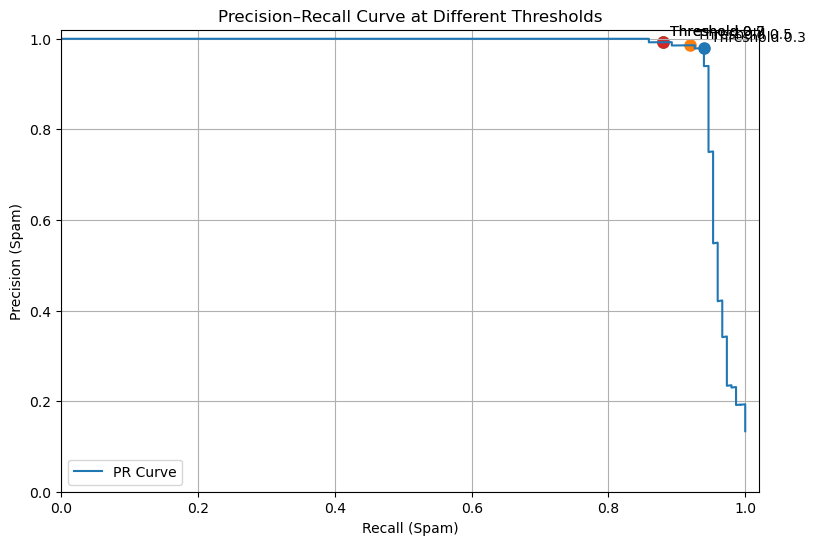

In [21]:
# B1 — code

# If model, vectorizer, X_test and y_test already exist
# from the previous MultinomialNB cell, run this section.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_score, recall_score, precision_recall_curve
)

# Get probability of spam
spam_index = list(model.classes_).index("spam")
spam_prob = model.predict_proba(
    vectorizer.transform(X_test)
)[:, spam_index]

y_true = (y_test == "spam").astype(int)
thresholds = [0.3, 0.5, 0.7, 0.9]

# (a) Precision and recall at each threshold
points = []

for t in thresholds:
    pred = (spam_prob >= t).astype(int)
    p = precision_score(y_true, pred, zero_division=0)
    r = recall_score(y_true, pred, zero_division=0)

    points.append((t, p, r))
    print(f"Threshold: {t:.1f} | Precision: {p:.4f} | Recall: {r:.4f}")

# (b) Precision-recall curve
precision, recall, _ = precision_recall_curve(y_true, spam_prob)

plt.figure(figsize=(9, 6))
plt.plot(recall, precision, label="PR Curve")

for t, p, r in points:
    plt.scatter(r, p, s=65)
    plt.annotate(
        f"Threshold {t}",
        (r, p),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Recall (Spam)")
plt.ylabel("Precision (Spam)")
plt.title("Precision–Recall Curve at Different Thresholds")
plt.xlim(0, 1.02)
plt.ylim(0, 1.02)
plt.grid(True)
plt.legend()
plt.show()


**Observation (B1):**

> *A false positive occurs when a legitimate message is incorrectly classified as spam.
> 
> A false negative occurs when a spam message is classified as legitimate.
> 
> In a real email or SMS filter, false positives can be particularly harmful because important messages may be hidden in the junk folder.
> 
> False negatives are also undesirable because unwanted or fraudulent messages may reach the inbox.
> 
> I would generally prioritize avoiding false positives so that legitimate messages remain accessible.
> 
> I would initially choose a threshold of 0.7 as a compromise between spam detection and protecting legitimate messages.
> 
> I would verify the actual precision and recall at 0.7 before deploying the filter.
> 
> If the precision is insufficient, I would raise the threshold; if too much spam is missed, I would consider lowering it.*

## B2. n-grams and vocabulary size  &nbsp;&nbsp;`[4 marks]`

*Dataset: C2.*

a. Fit the same classifier with `ngram_range` of (1,1), (1,2) and (1,3).
b. Report vocabulary size, F1 and fit time for each in one table.
c. Explain in 4–6 lines what bigrams add, and at what point the extra features stop paying for themselves.


In [ ]:
# B2 — code


**Observation (B2):**

> *write 2–6 lines here*

---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Break your own filter  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Write three spam messages by hand that your model classifies as ham.
b. In 4–6 lines, explain what property of bag-of-words you exploited and one defence against it.


In [22]:
# C1 — code
test_messages = [
    "Your account has been selected for a reward. Please share your bank details to receive it.",
    "You have won a free holiday. Send your personal information to claim your prize.",
    "Urgent account verification required. Visit this link and enter your password to avoid account closure."
]

X_manual = vectorizer.transform(test_messages)
predictions = model.predict(X_manual)

for i, (message, prediction) in enumerate(
    zip(test_messages, predictions), start=1
):
    print(f"Message {i}: {message}")
    print("Predicted label:", prediction)
    print()

Message 1: Your account has been selected for a reward. Please share your bank details to receive it.
Predicted label: spam

Message 2: You have won a free holiday. Send your personal information to claim your prize.
Predicted label: spam

Message 3: Urgent account verification required. Visit this link and enter your password to avoid account closure.
Predicted label: spam



**Observation (C1):**

1. Bag-of-words represents a message using individual word counts, ignoring word order and much of the context.
2. The model may fail to recognize malicious intent when a message uses ordinary words instead of familiar spam-related terms.
3. Rephrasing a spam message can therefore change its prediction even when its meaning remains suspicious.
4. One defence is to use word and character n-grams, which capture short sequences and parts of words.
5. Combining text features with URL, sender reputation, and suspicious-link detection can further improve spam identification.

---

## Self-check before submitting

- [x] Kernel restarted and run top-to-bottom, all outputs visible
- [x] Every attempted question has a written observation
- [x] No transformer fitted outside a pipeline
- [x] Metrics reported with units where they have any
- [x] File named `AML_LA06_<SAPID>.ipynb`
